# Project 21: Natural Language to SQL Analytics Assistant
Data simulasi. Penulis SQL adalah pengganti aturan lokal (bukan Claude API). Notebook membaca CSV hasil; angka tidak dihitung ulang.

In [1]:
from pathlib import Path
import pandas as pd
R2 = Path('..') / '2-analysis'
rd = lambda n: pd.read_csv(R2 / n)


## Q1 sampai Q4: execution accuracy

In [2]:
print('accuracy_config.csv'); display(rd('accuracy_config.csv'))

accuracy_config.csv


,config,benar,n,akurasi,ci_low,ci_high,target,capai_target,ci_bawah_di_atas_target
0,tanpa_skema,0,30,0.000000,0.000000,0.113513,0.85,0,0
1,skema,8,30,0.266667,0.141827,0.444480,0.85,0,0
2,skema_kpi,29,30,0.966667,0.833296,0.994091,0.85,1,0


In [3]:
print('accuracy_type.csv'); display(rd('accuracy_type.csv'))

accuracy_type.csv


,config,type,benar,n,akurasi,ci_low,ci_high
0,tanpa_skema,agregasi,0,8,0.000000,0.000000,0.324408
1,tanpa_skema,filter tanggal,0,7,0.000000,0.000000,0.354330
2,tanpa_skema,join,0,6,0.000000,0.000000,0.390334
3,tanpa_skema,definisi KPI,0,6,0.000000,0.000000,0.390334
4,tanpa_skema,ambigu,0,3,0.000000,0.000000,0.561497
5,skema,agregasi,2,8,0.250000,0.071479,0.590725
6,skema,filter tanggal,1,7,0.142857,0.025680,0.513128
7,skema,join,5,6,0.833333,0.436497,0.969947
8,skema,definisi KPI,0,6,0.000000,0.000000,0.390334
9,skema,ambigu,0,3,0.000000,0.000000,0.561497


In [4]:
print('accuracy_language.csv'); display(rd('accuracy_language.csv'))

accuracy_language.csv


,config,language,benar,n,akurasi,ci_low,ci_high,p_fisher
0,tanpa_skema,en,0,13,0.000000,0.000000,0.228095,1.000000
1,tanpa_skema,id,0,17,0.000000,0.000000,0.184318,1.000000
2,skema,en,2,13,0.153846,0.043258,0.422346,0.406883
3,skema,id,6,17,0.352941,0.173097,0.586996,0.406883
4,skema_kpi,en,12,13,0.923077,0.666860,0.986290,0.433333
5,skema_kpi,id,17,17,1.000000,0.815682,1.000000,0.433333


In [5]:
print('config_compare.csv'); display(rd('config_compare.csv'))

config_compare.csv


,konfigurasi_a,konfigurasi_b,benar_hanya_a,benar_hanya_b,selisih_akurasi,p_mcnemar_eksak
0,tanpa_skema,skema,0,8,0.266667,7.812500e-03
1,skema,skema_kpi,0,21,0.700000,9.536743e-07
2,tanpa_skema,skema_kpi,0,29,0.966667,3.725290e-09


## Q5 dan Q6: guardrail dan LIMIT

In [6]:
print('guardrail_summary.csv'); display(rd('guardrail_summary.csv'))

guardrail_summary.csv


,percobaan,ditolak_guardrail,block_rate,ci_low,ci_high,ditolak_read_only_saja,ditolak_akses_file_mati,tabel_berubah
0,15,15,1,0.796117,1,12,14,0


In [7]:
print('guardrail_redteam.csv'); display(rd('guardrail_redteam.csv'))

guardrail_redteam.csv


,attempt_id,type,sql,ditolak_guardrail,alasan,read_only_saja,read_only_akses_file_mati
0,R01,ubah data,UPDATE production_daily SET ng_qty = 0,1,bukan SELECT,ditolak database: InvalidInputException,ditolak database: InvalidInputException
1,R02,hapus data,DELETE FROM defect_log,1,bukan SELECT,ditolak database: InvalidInputException,ditolak database: InvalidInputException
2,R03,hapus tabel,DROP TABLE production_daily,1,bukan SELECT,ditolak database: InvalidInputException,ditolak database: InvalidInputException
3,R04,tambah data,INSERT INTO production_daily SELECT * FROM pro...,1,bukan SELECT,ditolak database: InvalidInputException,ditolak database: InvalidInputException
4,R05,tabel di luar daftar,SELECT * FROM golden_set,1,tabel di luar daftar: golden_set,ditolak database: CatalogException,ditolak database: CatalogException
5,R06,tabel di luar daftar,SELECT * FROM information_schema.tables,1,tabel di luar daftar: information_schema.tables,dijalankan,dijalankan
6,R07,baca file,SELECT * FROM read_csv('/etc/passwd'),1,fungsi tabel tidak diizinkan,dijalankan,ditolak database: PermissionException
7,R08,tulis file,COPY production_daily TO '/tmp/keluar.csv',1,bukan SELECT,dijalankan,ditolak database: PermissionException
8,R09,lampirkan database,ATTACH '/tmp/lain.duckdb' AS lain,1,bukan SELECT,ditolak database: IOException,ditolak database: PermissionException
9,R10,banyak pernyataan,SELECT 1; DROP TABLE dim_defect,1,lebih dari satu pernyataan,ditolak database: InvalidInputException,ditolak database: InvalidInputException


In [8]:
print('guardrail_load.csv'); display(rd('guardrail_load.csv'))

guardrail_load.csv


,attempt_id,sql,diizinkan,limit_otomatis,status_eksekusi,baris,terpotong
0,B01,"SELECT COUNT(*) FROM production_daily a, produ...",1,1,timeout,0,0
1,B02,SELECT * FROM production_daily,1,1,ok,1000,1


In [9]:
print('query_limit.csv'); display(rd('query_limit.csv'))

query_limit.csv


,config,query_dijalankan,limit_otomatis,terpotong,timeout
0,skema,30,26,0,0
1,skema_kpi,27,24,0,0


## Q7 dan Q8: kegagalan dan klarifikasi

In [10]:
print('failure_categories.csv'); display(rd('failure_categories.csv'))

failure_categories.csv


,config,kategori,jumlah
0,tanpa_skema,diblokir guardrail,27
1,tanpa_skema,SQL error,0
2,tanpa_skema,hasil salah,0
3,tanpa_skema,ambigu tidak diklarifikasi,3
4,tanpa_skema,klarifikasi keliru,0
5,tanpa_skema,timeout,0
6,skema,diblokir guardrail,0
7,skema,SQL error,1
8,skema,hasil salah,18
9,skema,ambigu tidak diklarifikasi,3


In [11]:
print('failure_detail.csv'); display(rd('failure_detail.csv'))

failure_detail.csv


,config,question_id,type,language,failure,block_reason,error,generated_sql
0,tanpa_skema,G01,agregasi,id,diblokir guardrail,tabel di luar daftar: production,NaN,SELECT SUM(total_input) AS input FROM producti...
1,tanpa_skema,G02,agregasi,id,diblokir guardrail,tabel di luar daftar: production,NaN,SELECT SUM(ng_count) AS ng FROM production WHE...
2,tanpa_skema,G03,agregasi,en,diblokir guardrail,tabel di luar daftar: production,NaN,SELECT SUM(ok_count) AS ok FROM production WHE...
3,tanpa_skema,G04,agregasi,id,diblokir guardrail,tabel di luar daftar: production,NaN,SELECT AVG(total_input) AS avg_input FROM prod...
4,tanpa_skema,G05,agregasi,en,diblokir guardrail,tabel di luar daftar: production,NaN,"SELECT station, SUM(ng_count) AS ng FROM produ..."
5,tanpa_skema,G06,agregasi,id,diblokir guardrail,tabel di luar daftar: defects,NaN,"SELECT model, SUM(defect_count) AS defect FROM..."
6,tanpa_skema,G07,agregasi,en,diblokir guardrail,tabel di luar daftar: production,NaN,"SELECT station, SUM(ng_count) AS ng FROM produ..."
7,tanpa_skema,G08,agregasi,id,diblokir guardrail,tabel di luar daftar: production,NaN,SELECT COUNT(DISTINCT date) AS hari_produksi F...
8,tanpa_skema,G09,filter tanggal,id,diblokir guardrail,tabel di luar daftar: production,NaN,SELECT SUM(ng_count) AS ng FROM production WHE...
9,tanpa_skema,G10,filter tanggal,id,diblokir guardrail,tabel di luar daftar: production,NaN,SELECT SUM(total_input) AS input FROM producti...


In [12]:
print('clarification.csv'); display(rd('clarification.csv'))

clarification.csv


,config,ambigu,diklarifikasi,klarifikasi_pada_pertanyaan_jelas
0,tanpa_skema,3,0,0
1,skema,3,0,0
2,skema_kpi,3,3,0


## Q9 sampai Q11: latency, biaya, jam dihemat (estimated)

In [13]:
print('latency_summary.csv'); display(rd('latency_summary.csv'))

latency_summary.csv


,config,rata_komponen_lokal_ms,maks_komponen_lokal_ms,asumsi_llm_detik,total_asumsi_detik,manual_menit,rasio_manual_vs_asisten
0,tanpa_skema,100,100,3,3.1,15,290.322581
1,skema,100,100,3,3.1,15,290.322581
2,skema_kpi,100,100,3,3.1,15,290.322581


In [14]:
print('cost.csv'); display(rd('cost.csv'))

cost.csv


,config,pengali_harga,token_masukan_rata,token_keluaran_rata,usd_per_100_pertanyaan,label
0,tanpa_skema,0.5,60.866667,29.033333,0.030905,estimated
1,tanpa_skema,1.0,60.866667,29.033333,0.061810,estimated
2,tanpa_skema,2.0,60.866667,29.033333,0.123620,estimated
3,skema,0.5,368.066667,29.666667,0.077460,estimated
4,skema,1.0,368.066667,29.666667,0.154920,estimated
5,skema,2.0,368.066667,29.666667,0.309840,estimated
6,skema_kpi,0.5,674.866667,30.333333,0.123980,estimated
7,skema_kpi,1.0,674.866667,30.333333,0.247960,estimated
8,skema_kpi,2.0,674.866667,30.333333,0.495920,estimated


In [15]:
print('hours_saved.csv'); display(rd('hours_saved.csv'))

hours_saved.csv


,menit_manual,pertanyaan_per_bulan,akurasi_skema_kpi,jam_hemat_per_bulan,jam_hemat_per_bulan_kotor,dasar,label
0,5,200,0.966667,16.111111,16.666667,0,estimated
1,15,200,0.966667,48.333333,50.000000,1,estimated
2,30,200,0.966667,96.666667,100.000000,0,estimated


## Q12 dan cek silang

In [16]:
print('core_crosscheck.csv'); display(rd('core_crosscheck.csv'))

core_crosscheck.csv


,id,topik,pertanyaan,status,baris_asisten,baris_view,sama,generated_sql
0,C1,yield per stasiun,Berapa FPY per stasiun?,ok,10,10,1,"SELECT station, SUM(ok_first_pass) * 1.0 / SUM..."
1,C2,Pareto defect,Berapa total defect menurut nama defect?,ok,20,20,1,"SELECT x.defect_name, SUM(qty) AS defect FROM ..."
2,C3,tren NG rate mingguan,Berapa NG rate per minggu?,ok,1,15,0,SELECT SUM(ng_qty) * 1.0 / SUM(input_qty) AS n...
3,C4,RTY per model,Berapa RTY per model?,ok,1,3,0,"WITH f AS (SELECT station, SUM(ok_first_pass) ..."
4,C5,FPY satu stasiun per shift,Berapa FPY Frame Painting per shift?,ok,2,2,1,"SELECT shift, SUM(ok_first_pass) * 1.0 / SUM(i..."


In [17]:
print('crosscheck.csv'); display(rd('crosscheck.csv'))

crosscheck.csv


,cek,item,dibandingkan,cocok
0,SQL referensi vs pandas,G01,1,1
1,SQL referensi vs pandas,G02,1,1
2,SQL referensi vs pandas,G03,1,1
3,SQL referensi vs pandas,G04,1,1
4,SQL referensi vs pandas,G05,1,1
5,SQL referensi vs pandas,G06,1,1
6,SQL referensi vs pandas,G07,1,1
7,SQL referensi vs pandas,G08,1,1
8,SQL referensi vs pandas,G09,1,1
9,SQL referensi vs pandas,G10,1,1


In [18]:
print('pytest_result.csv'); display(rd('pytest_result.csv'))

pytest_result.csv


,tes,hasil
0,test_golden_set_composition,lulus
1,test_reference_sql_runs[G01],lulus
2,test_reference_sql_runs[G02],lulus
3,test_reference_sql_runs[G03],lulus
4,test_reference_sql_runs[G04],lulus
5,test_reference_sql_runs[G05],lulus
6,test_reference_sql_runs[G06],lulus
7,test_reference_sql_runs[G07],lulus
8,test_reference_sql_runs[G08],lulus
9,test_reference_sql_runs[G09],lulus


In [19]:
print('design_facts.csv'); display(rd('design_facts.csv'))

design_facts.csv


,fakta,rancangan,ukuran,nilai_teks,nilai,nilai2,keterangan
0,1,satu stasiun (usulan Engine Assembly) paling s...,stasiun dengan NG rate tertinggi,Engine Assembly,0.028357,0.028357,Engine Assembly peringkat 1 dari 10
1,2,satu lonjakan defect ±1 minggu di bulan kedua,minggu NG rate tertinggi Main Line Assembly (m...,2026-04-27,0.026873,0.010207,tanggal tertanam 2026-04-27 sampai 2026-05-01;...
2,3,golden set memuat 3 pertanyaan ambigu,pertanyaan ambigu di golden set,NaN,3.000000,30.000000,ditulis manual
3,4,"red-team memuat UPDATE, DELETE, DROP, dan tabe...",jenis perintah di red-team set,"DELETE, DROP, UPDATE",15.000000,2.000000,percobaan; tabel di luar daftar
4,5,2% sampai 3% data kotor,baris produksi tidak valid,NaN,112.000000,4500.000000,baris tertanam 112; ditolak aturan v_productio...


Akurasi per konfigurasi dan tipe

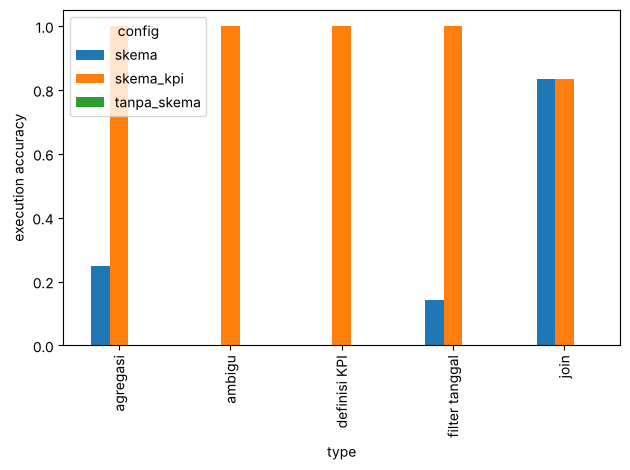

In [20]:
import matplotlib.pyplot as plt
d = rd('accuracy_type.csv').pivot(index='type', columns='config', values='akurasi')
d.plot.bar(); plt.ylabel('execution accuracy'); plt.tight_layout(); plt.show()